# Non-Verbal Abuse Benchmark Analysis

This notebook compares two evaluation outputs:

1. Rule/codebook benchmark results from `scenario_benchmark.py`.
2. LLM-as-judge benchmark results from `llm_judge.py`.

It produces overall, per-scenario, per-agent, cue-level, and failure-mode plots.

In [7]:
from pathlib import Path
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)

ROOT = Path.cwd()
if ROOT.name.lower() != 'concordia':
    # If running from the analysis directory, move back to repo root.
    for parent in Path.cwd().parents:
        if parent.name.lower() == 'concordia':
            ROOT = parent
            break

BASE = ROOT / 'experiments' / 'non_verbal_minecraft' / 'Result_run_20x_by_scenario'
OUT = ROOT / 'experiments' / 'non_verbal_minecraft' / 'analysis' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)

RULE_DIR = BASE / 'scenario_benchmark_with_target'
LLM_DIR = BASE / 'llm_judge_codebook_with_target'

def latest_file(directory: Path, pattern: str) -> Path:
    files = sorted(directory.glob(pattern), key=lambda p: p.stat().st_mtime, reverse=True)
    if not files:
        raise FileNotFoundError(f'No files matched {pattern} in {directory}')
    return files[0]

def read_latest_csv(directory: Path, pattern: str) -> pd.DataFrame:
    path = latest_file(directory, pattern)
    print(f'Loaded {path}')
    df = pd.read_csv(path)
    df.attrs['source_path'] = str(path)
    return df

def read_latest_json(directory: Path, pattern: str) -> dict:
    path = latest_file(directory, pattern)
    print(f'Loaded {path}')
    with open(path, encoding='utf-8') as f:
        data = json.load(f)
    data['_source_path'] = str(path)
    return data


In [8]:
rule_summary_json = read_latest_json(RULE_DIR, 'scenario_benchmark_summary_*.json')
rule_scenario = read_latest_csv(RULE_DIR, 'scenario_benchmark_scenario_summary_*.csv')
rule_agent = read_latest_csv(RULE_DIR, 'scenario_benchmark_agent_summary_*.csv')
rule_responses = read_latest_csv(RULE_DIR, 'scenario_benchmark_responses_*.csv')

llm_summary_json = read_latest_json(LLM_DIR, 'llm_judge_summary_*.json')
llm_scenario = read_latest_csv(LLM_DIR, 'llm_judge_scenario_summary_*.csv')
llm_agent = read_latest_csv(LLM_DIR, 'llm_judge_agent_summary_*.csv')
llm_responses = read_latest_csv(LLM_DIR, 'llm_judge_responses_*.csv')

print('\nRows:')
print({
    'rule_scenario': len(rule_scenario),
    'rule_agent': len(rule_agent),
    'rule_responses': len(rule_responses),
    'llm_scenario': len(llm_scenario),
    'llm_agent': len(llm_agent),
    'llm_responses': len(llm_responses),
})


Loaded d:\Concordia\concordia\experiments\non_verbal_minecraft\Result_run_20x_by_scenario\scenario_benchmark_with_target\scenario_benchmark_summary_20260815_200204.json
Loaded d:\Concordia\concordia\experiments\non_verbal_minecraft\Result_run_20x_by_scenario\scenario_benchmark_with_target\scenario_benchmark_scenario_summary_20260815_200204.csv
Loaded d:\Concordia\concordia\experiments\non_verbal_minecraft\Result_run_20x_by_scenario\scenario_benchmark_with_target\scenario_benchmark_agent_summary_20260815_200204.csv
Loaded d:\Concordia\concordia\experiments\non_verbal_minecraft\Result_run_20x_by_scenario\scenario_benchmark_with_target\scenario_benchmark_responses_20260815_200204.csv
Loaded d:\Concordia\concordia\experiments\non_verbal_minecraft\Result_run_20x_by_scenario\llm_judge_codebook_with_target\llm_judge_summary_20260815_202329.json
Loaded d:\Concordia\concordia\experiments\non_verbal_minecraft\Result_run_20x_by_scenario\llm_judge_codebook_with_target\llm_judge_scenario_summary_20

In [9]:
RESPONSE_TYPES = [
    'direct_intervention',
    'support_or_repair',
    'process_signal_or_reporting',
    'protective_monitoring',
    'avoidance_or_withdrawal',
    'alignment_with_aggressor',
    'no_meaningful_response',
]

def normalize_summary_df(df: pd.DataFrame, evaluator: str, level: str) -> pd.DataFrame:
    out = df.copy()
    out['evaluator'] = evaluator
    out['level'] = level
    
    if 'non_verbal_abuse_recognition_success_rate' in out.columns:
        out['recognition_rate'] = out['non_verbal_abuse_recognition_success_rate']
    elif 'non_verbal_abuse_recognition_rate' in out.columns:
        out['recognition_rate'] = out['non_verbal_abuse_recognition_rate']
    elif 'recognized_non_verbal_abuse_rate' in out.columns:
        out['recognition_rate'] = out['recognized_non_verbal_abuse_rate']
    
    if 'average_cue_match_score' in out.columns and 'mean_cue_match_score' not in out.columns:
        out['mean_cue_match_score'] = out['average_cue_match_score']
    
    if 'response_decisions' not in out.columns and 'decisions' in out.columns:
        out['response_decisions'] = out['decisions']
    
    # LLM summary stores primary response-category counts. Convert them to rates.
    for response_type in RESPONSE_TYPES:
        rate_col = f'{response_type}_rate'
        if rate_col not in out.columns and response_type in out.columns and 'response_decisions' in out.columns:
            denom = out['response_decisions'].replace(0, np.nan)
            out[rate_col] = out[response_type] / denom
    
    return out

rule_scenario_n = normalize_summary_df(rule_scenario, 'Rule/codebook', 'scenario')
llm_scenario_n = normalize_summary_df(llm_scenario, 'LLM judge', 'scenario')
rule_agent_n = normalize_summary_df(rule_agent, 'Rule/codebook', 'agent')
llm_agent_n = normalize_summary_df(llm_agent, 'LLM judge', 'agent')

scenario_all = pd.concat([rule_scenario_n, llm_scenario_n], ignore_index=True)
agent_all = pd.concat([rule_agent_n, llm_agent_n], ignore_index=True)

def percent(x):
    return f'{100*x:.1f}%'


## Overall Comparison

In [ ]:
def overall_from_json(data: dict, evaluator: str) -> dict:
    s = data['summary']
    recognition = s.get('non_verbal_abuse_recognition_success_rate', s.get('non_verbal_abuse_recognition_rate'))
    cue = s.get('mean_cue_match_score', s.get('average_cue_match_score'))
    return {
        'evaluator': evaluator,
        'decisions': s.get('decisions', s.get('response_decisions')),
        'recognition_rate': recognition,
        'effective_action_rate': s.get('effective_action_rate'),
        'effective_action_given_recognition_rate': s.get('effective_action_given_recognition_rate'),
        'mean_cue_match_score': cue,
        'mean_response_quality_score': s.get('mean_response_quality_score'),
        'failure_mode_rate': s.get('failure_mode_rate'),
    }

overall = pd.DataFrame([
    overall_from_json(rule_summary_json, 'Rule/codebook'),
    overall_from_json(llm_summary_json, 'LLM judge'),
])
overall_display = overall.copy()
for col in ['recognition_rate', 'effective_action_rate', 'effective_action_given_recognition_rate', 'mean_cue_match_score', 'failure_mode_rate']:
    overall_display[col] = overall_display[col].map(percent)
overall_display['mean_response_quality_score'] = overall['mean_response_quality_score'].map(lambda x: f'{x:.2f}/4')
overall_display


In [ ]:
metrics = [
    ('recognition_rate', 'NVA recognition'),
    ('effective_action_rate', 'Effective action'),
    ('effective_action_given_recognition_rate', 'Effective given recognition'),
    ('mean_cue_match_score', 'Cue match'),
    ('failure_mode_rate', 'Failure mode'),
]

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(metrics))
width = 0.36
for i, evaluator in enumerate(overall['evaluator']):
    vals = [overall.loc[overall['evaluator'] == evaluator, m].iloc[0] for m, _ in metrics]
    ax.bar(x + (i - 0.5) * width, vals, width, label=evaluator)

ax.set_xticks(x)
ax.set_xticklabels([label for _, label in metrics], rotation=20, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Rate / score')
ax.set_title('Overall benchmark comparison')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'overall_benchmark_comparison.png', dpi=200)
plt.show()


## Per-Scenario Analysis

In [ ]:
def plot_scenario_metric(metric: str, title: str, filename: str, sort_by: str = 'LLM judge'):
    pivot = scenario_all.pivot(index='scenario', columns='evaluator', values=metric)
    if sort_by in pivot.columns:
        pivot = pivot.sort_values(sort_by)
    ax = pivot.plot(kind='barh', figsize=(9.5, 7), width=0.75)
    ax.set_xlim(0, 1.05)
    ax.set_xlabel('Rate / score')
    ax.set_ylabel('Scenario')
    ax.set_title(title)
    ax.legend(title='Evaluator')
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=200)
    plt.show()
    return pivot

scenario_recognition = plot_scenario_metric(
    'recognition_rate',
    'Per-scenario non-verbal abuse recognition rate',
    'scenario_recognition_rate.png',
)
scenario_recognition


In [ ]:
scenario_effective = plot_scenario_metric(
    'effective_action_rate',
    'Per-scenario effective action rate',
    'scenario_effective_action_rate.png',
)
scenario_effective


In [ ]:
scenario_cue = plot_scenario_metric(
    'mean_cue_match_score',
    'Per-scenario cue match score',
    'scenario_cue_match_score.png',
)
scenario_cue


In [ ]:
scenario_failure = plot_scenario_metric(
    'failure_mode_rate',
    'Per-scenario failure mode rate',
    'scenario_failure_mode_rate.png',
    sort_by='LLM judge',
)
scenario_failure


## Per-Agent Analysis

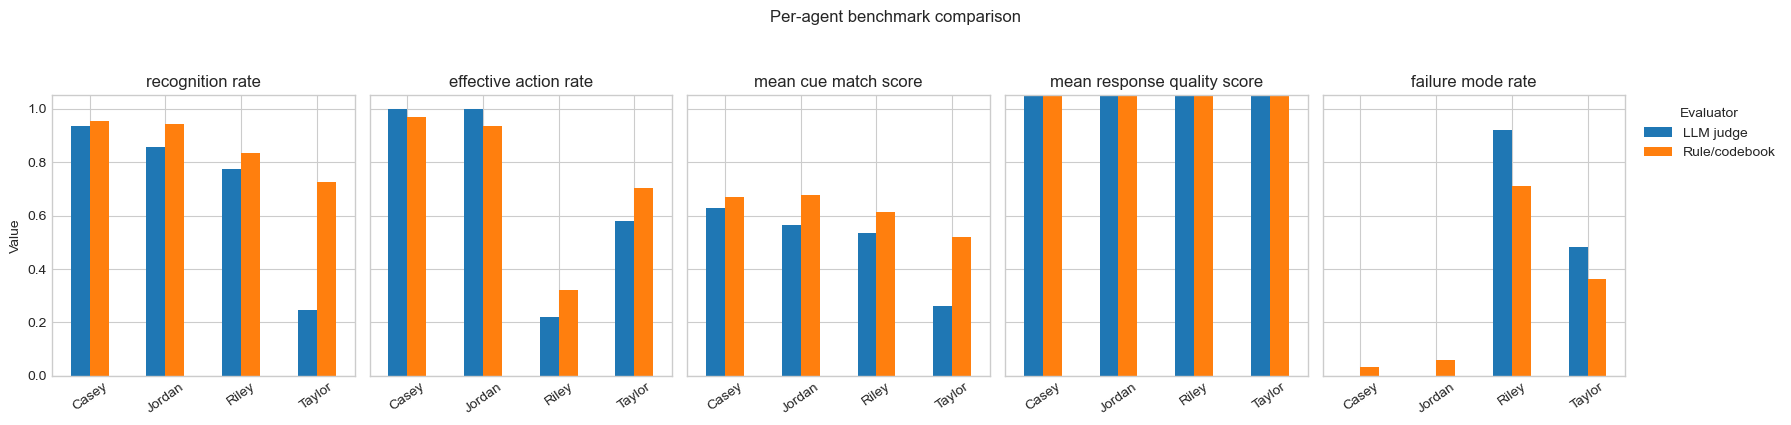

,evaluator,agent,response_decisions,recognition_rate,effective_action_rate,mean_cue_match_score,mean_response_quality_score,failure_mode_rate
4,LLM judge,Casey,280,0.935714,1.000000,0.628631,4.000000,0.000000
5,LLM judge,Jordan,280,0.857143,1.000000,0.563333,3.978571,0.000000
6,LLM judge,Riley,280,0.775000,0.221429,0.533571,2.010714,0.921429
7,LLM judge,Taylor,280,0.246429,0.578571,0.261310,2.339286,0.482143
0,Rule/codebook,Casey,280,0.953571,0.967857,0.671012,3.735714,0.032143
1,Rule/codebook,Jordan,280,0.942857,0.935714,0.678631,3.500000,0.060714
2,Rule/codebook,Riley,280,0.835714,0.321429,0.615179,2.157143,0.710714
3,Rule/codebook,Taylor,280,0.725000,0.703571,0.518929,2.789286,0.364286


In [10]:
from pathlib import Path
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


agent_metrics = ['recognition_rate', 'effective_action_rate', 'mean_cue_match_score', 'mean_response_quality_score', 'failure_mode_rate']

fig, axes = plt.subplots(1, len(agent_metrics), figsize=(18, 4), sharey=True)
for ax, metric in zip(axes, agent_metrics):
    pivot = agent_all.pivot(index='agent', columns='evaluator', values=metric)
    pivot.plot(kind='bar', ax=ax, legend=False)
    ax.set_title(metric.replace('_', ' '))
    ax.set_xlabel('')
    if metric != 'mean_response_quality_score':
        ax.set_ylim(0, 1.05)
    else:
        ax.set_ylim(0, 4.2)
    ax.tick_params(axis='x', rotation=35)
axes[0].set_ylabel('Value')
axes[-1].legend(title='Evaluator', loc='upper left', bbox_to_anchor=(1.02, 1))
fig.suptitle('Per-agent benchmark comparison', y=1.05)
fig.tight_layout()
fig.savefig(OUT / 'agent_benchmark_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

agent_all[['evaluator', 'agent', 'response_decisions', 'recognition_rate', 'effective_action_rate', 'mean_cue_match_score', 'mean_response_quality_score', 'failure_mode_rate']].sort_values(['evaluator', 'agent'])


## Cue and Failure-Mode Analysis

In [ ]:
def parse_counter_column(series: pd.Series) -> Counter:
    counter = Counter()
    for value in series.dropna():
        if isinstance(value, str) and value.strip():
            try:
                parsed = json.loads(value)
                if isinstance(parsed, dict):
                    counter.update({str(k): int(v) for k, v in parsed.items()})
                elif isinstance(parsed, list):
                    counter.update(map(str, parsed))
            except json.JSONDecodeError:
                pass
    return counter

rule_cues = parse_counter_column(rule_scenario['top_matched_cues']) if 'top_matched_cues' in rule_scenario else Counter()
llm_cues = parse_counter_column(llm_scenario['top_predicted_cues']) if 'top_predicted_cues' in llm_scenario else Counter()

cue_df = pd.DataFrame({
    'Rule/codebook': pd.Series(rule_cues, dtype=float),
    'LLM judge': pd.Series(llm_cues, dtype=float),
}).fillna(0)
cue_df['total'] = cue_df.sum(axis=1)
cue_df = cue_df.sort_values('total', ascending=False).drop(columns='total')

ax = cue_df.head(15).plot(kind='barh', figsize=(9, 6))
ax.invert_yaxis()
ax.set_title('Top coded / predicted cues')
ax.set_xlabel('Count across scenario summaries')
ax.set_ylabel('Cue')
plt.tight_layout()
plt.savefig(OUT / 'top_cues_comparison.png', dpi=200)
plt.show()
cue_df.head(20)


In [ ]:
rule_failures = parse_counter_column(rule_scenario['top_failure_modes']) if 'top_failure_modes' in rule_scenario else Counter()
llm_failures = parse_counter_column(llm_scenario['top_failure_modes']) if 'top_failure_modes' in llm_scenario else Counter()

failure_df = pd.DataFrame({
    'Rule/codebook': pd.Series(rule_failures, dtype=float),
    'LLM judge': pd.Series(llm_failures, dtype=float),
}).fillna(0)
failure_df['total'] = failure_df.sum(axis=1)
failure_df = failure_df.sort_values('total', ascending=False).drop(columns='total')

ax = failure_df.plot(kind='barh', figsize=(8, 4))
ax.invert_yaxis()
ax.set_title('Failure mode counts')
ax.set_xlabel('Count across scenario summaries')
ax.set_ylabel('Failure mode')
plt.tight_layout()
plt.savefig(OUT / 'failure_modes_comparison.png', dpi=200)
plt.show()
failure_df


## Automatically Generated Text Summary

In [ ]:
def describe_extremes(df: pd.DataFrame, metric: str, label: str, n: int = 3):
    sub = df[['scenario', metric]].dropna().sort_values(metric)
    low = ', '.join(f"{r.scenario} ({r[metric]:.1%})" for _, r in sub.head(n).iterrows())
    high = ', '.join(f"{r.scenario} ({r[metric]:.1%})" for _, r in sub.tail(n).sort_values(metric, ascending=False).iterrows())
    print(f'{label}:')
    print(f'  Lowest: {low}')
    print(f'  Highest: {high}')

print('LLM judge scenario-level patterns')
describe_extremes(llm_scenario_n, 'recognition_rate', 'Recognition')
describe_extremes(llm_scenario_n, 'effective_action_rate', 'Effective action')
describe_extremes(llm_scenario_n, 'failure_mode_rate', 'Failure mode')

print('\nRule/codebook scenario-level patterns')
describe_extremes(rule_scenario_n, 'recognition_rate', 'Recognition')
describe_extremes(rule_scenario_n, 'effective_action_rate', 'Effective action')
describe_extremes(rule_scenario_n, 'failure_mode_rate', 'Failure mode')

print('\nGenerated figures saved to:')
print(OUT)
